In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, precision_score,recall_score,f1_score

In [13]:
df = pd.read_csv('credit_card_fraud_drift_2026.csv')
df.head()

,transaction_id,customer_id,card_id,merchant_id,transaction_datetime,month,week_of_year,drift_phase,days_into_phase,drift_magnitude,...,drift_phase_name,post_transaction_outcome,transaction_time_eligible,transaction_time_target,dispute_filed,dispute_adjudicated_friendly_fraud,dispute_delay_days,dispute_event_datetime,adjudication_datetime,dispute_regime
0,TX4042000000000,CU00022008,CA000000001,ME000381,2026-01-01 00:00:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
1,TX4042000000001,CU00000598,CA000000002,ME000764,2026-01-01 00:00:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
2,TX4042000000002,CU00018179,CA000000003,ME001251,2026-01-01 00:03:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
3,TX4042000000003,CU00023636,CA000000004,ME002627,2026-01-01 00:04:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
4,TX4042000000004,CU00028521,CA000000005,ME004940,2026-01-01 00:05:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period


In [14]:
df.tail()

,transaction_id,customer_id,card_id,merchant_id,transaction_datetime,month,week_of_year,drift_phase,days_into_phase,drift_magnitude,...,drift_phase_name,post_transaction_outcome,transaction_time_eligible,transaction_time_target,dispute_filed,dispute_adjudicated_friendly_fraud,dispute_delay_days,dispute_event_datetime,adjudication_datetime,dispute_regime
119995,TX4042000119995,CU00028819,CA000006557,ME003141,2026-06-30 23:53:00,6,27,4,29,0.48,...,partial_stabilization,0,1,Legitimate,0,0,NaN,NaN,NaN,later_period
119996,TX4042000119996,CU00027633,CA000006431,ME000713,2026-06-30 23:54:00,6,27,4,29,0.48,...,partial_stabilization,0,1,Legitimate,0,0,NaN,NaN,NaN,later_period
119997,TX4042000119997,CU00007909,CA000007841,ME002856,2026-06-30 23:55:00,6,27,4,29,0.48,...,partial_stabilization,0,1,Legitimate,0,0,NaN,NaN,NaN,later_period
119998,TX4042000119998,CU00025126,CA000009491,ME004006,2026-06-30 23:57:00,6,27,4,29,0.48,...,partial_stabilization,0,1,Legitimate,0,0,NaN,NaN,NaN,later_period
119999,TX4042000119999,CU00014288,CA000029099,ME003500,2026-06-30 23:58:00,6,27,4,29,0.48,...,partial_stabilization,0,1,Legitimate,0,0,NaN,NaN,NaN,later_period


In [15]:
df.shape

(120000, 73)

In [16]:
df.columns

Index(['transaction_id', 'customer_id', 'card_id', 'merchant_id',
       'transaction_datetime', 'month', 'week_of_year', 'drift_phase',
       'days_into_phase', 'drift_magnitude', 'transaction_amount',
       'merchant_category', 'merchant_country', 'transaction_hour',
       'transaction_day_of_week', 'card_present', 'customer_age',
       'customer_gender', 'customer_country', 'account_age_days',
       'credit_limit', 'credit_score', 'num_cards_held',
       'transactions_last_1h', 'transactions_last_24h', 'transactions_last_7d',
       'amount_last_1h', 'amount_last_24h', 'days_since_last_transaction',
       'distance_from_home_km', 'distance_from_last_tx_km',
       'international_transaction', 'high_risk_country', 'amount_vs_avg_ratio',
       'used_chip', 'used_pin', 'transaction_channel', 'device_type',
       'browser', 'is_weekend', 'avg_transaction_amount_30d',
       'std_transaction_amount_30d', 'num_declined_last_30d',
       'num_chargebacks_ever', 'email_domain', 'fa

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 73 columns):
 #   Column                              Non-Null Count   Dtype  
---  ------                              --------------   -----  
 0   transaction_id                      120000 non-null  object 
 1   customer_id                         120000 non-null  object 
 2   card_id                             120000 non-null  object 
 3   merchant_id                         120000 non-null  object 
 4   transaction_datetime                120000 non-null  object 
 5   month                               120000 non-null  int64  
 6   week_of_year                        120000 non-null  int64  
 7   drift_phase                         120000 non-null  int64  
 8   days_into_phase                     120000 non-null  int64  
 9   drift_magnitude                     120000 non-null  float64
 10  transaction_amount                  120000 non-null  float64
 11  merchant_category         

In [18]:
df.describe()

,month,week_of_year,drift_phase,days_into_phase,drift_magnitude,transaction_amount,transaction_hour,card_present,customer_age,account_age_days,...,label_available,label_delay_days,pseudo_label,is_fraud,fraud_amount_lost,post_transaction_outcome,transaction_time_eligible,dispute_filed,dispute_adjudicated_friendly_fraud,dispute_delay_days
count,120000.000000,120000.00000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,...,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,2693.000000
mean,3.509708,13.86245,2.342708,24.584083,0.316672,46.327703,11.466783,0.488842,41.858283,846.398217,...,0.900583,11.804117,-0.891217,0.094892,4.295675,0.004392,0.984225,0.022442,0.008500,30.857779
std,1.709794,7.47403,1.099130,16.560963,0.326347,36.972352,6.912716,0.499878,13.442005,916.128151,...,0.299222,13.943989,0.340123,0.293066,17.700369,0.066124,0.124604,0.148116,0.091803,17.349079
min,1.000000,1.00000,1.000000,0.000000,0.000000,1.500000,0.000000,0.000000,18.000000,15.000000,...,0.000000,0.000000,-1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,7.00000,1.000000,11.000000,0.000000,22.720000,5.000000,0.000000,32.000000,311.000000,...,1.000000,0.000000,-1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,16.000000
50%,4.000000,14.00000,3.000000,22.000000,0.480000,36.290000,11.000000,0.000000,42.000000,537.000000,...,1.000000,7.000000,-1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,31.000000
75%,5.000000,20.00000,3.000000,37.000000,0.620000,57.900000,17.000000,1.000000,51.000000,1014.000000,...,1.000000,21.000000,-1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,46.000000
max,6.000000,27.00000,4.000000,60.000000,0.780000,1030.590000,23.000000,1.000000,90.000000,24603.000000,...,1.000000,45.000000,1.000000,1.000000,504.800000,1.000000,1.000000,1.000000,1.000000,60.000000


In [19]:
df.isnull().sum()

,0
transaction_id,0
customer_id,0
card_id,0
merchant_id,0
transaction_datetime,0
...,...
dispute_adjudicated_friendly_fraud,0
dispute_delay_days,117307
dispute_event_datetime,117307
adjudication_datetime,117307


In [20]:
df.duplicated().sum()

np.int64(0)

In [21]:
df_clean =df.copy()

In [22]:
df_clean.dtypes

,0
transaction_id,object
customer_id,object
card_id,object
merchant_id,object
transaction_datetime,object
...,...
dispute_adjudicated_friendly_fraud,int64
dispute_delay_days,float64
dispute_event_datetime,object
adjudication_datetime,object


In [23]:
df_clean['transaction_datetime'] = pd.to_datetime(df_clean['transaction_datetime'])
df_clean['dispute_event_datetime'] = pd.to_datetime(df_clean['dispute_event_datetime'])
df_clean['adjudication_datetime'] = pd.to_datetime(df_clean['adjudication_datetime'])

In [24]:
df_clean[['transaction_datetime','dispute_event_datetime','adjudication_datetime']].dtypes

,0
transaction_datetime,datetime64[ns]
dispute_event_datetime,datetime64[ns]
adjudication_datetime,datetime64[ns]


In [25]:
df_clean[['transaction_amount','customer_age','credit_limit','credit_score']].describe()

,transaction_amount,customer_age,credit_limit,credit_score
count,120000.000000,120000.000000,120000.000000,120000.000000
mean,46.327703,41.858283,6723.963638,688.698575
std,36.972352,13.442005,5465.590540,64.415753
min,1.500000,18.000000,500.000000,300.000000
25%,22.720000,32.000000,3202.400000,646.000000
50%,36.290000,42.000000,5200.110000,689.000000
75%,57.900000,51.000000,8434.147500,732.000000
max,1030.590000,90.000000,73621.860000,850.000000


In [26]:
df_clean['fraud_type'].value_counts()

,count
fraud_type,
Legitimate,108613
Card-Not-Present,2879
Account-Takeover,2571
Synthetic-Identity,2146
Card-Present,1898
Friendly-Fraud,1893


In [27]:
df_clean['customer_gender'].value_counts()

,count
customer_gender,
F,58506
M,55944
unknown,3294
X,2256


In [28]:
df_clean['transaction_channel'].value_counts()

,count
transaction_channel,
POS,50226
ecommerce,35375
mobile_app,19942
ATM,8230
recurring,6227


In [29]:
df_clean['is_fraud'].value_counts()

,count
is_fraud,
0,108613
1,11387


In [30]:
fraud = df_clean[df_clean['is_fraud'] == 1]
legitimate = df_clean[df_clean['is_fraud'] == 0]

In [31]:
print("fradulent_transactions:", len(fraud))
print("legimate_transactions:", len(legitimate))

fradulent_transactions: 11387
legimate_transactions: 108613


In [32]:
fraud['fraud_type'].value_counts()

,count
fraud_type,
Card-Not-Present,2879
Account-Takeover,2571
Synthetic-Identity,2146
Card-Present,1898
Friendly-Fraud,1893


In [33]:
df_clean.groupby('fraud_type')['transaction_amount'].describe()

,count,mean,std,min,25%,50%,75%,max
fraud_type,,,,,,,,
Account-Takeover,2571.0,80.219996,60.048942,5.46,40.5350,62.850,100.8350,550.67
Card-Not-Present,2879.0,73.821452,58.283076,6.40,37.1250,58.130,91.5650,1030.59
Card-Present,1898.0,56.277160,42.527023,6.90,28.7325,44.720,70.4100,355.10
Friendly-Fraud,1893.0,62.351236,45.696800,4.05,31.2300,50.440,78.5000,381.90
Legitimate,108613.0,43.887321,33.779891,1.50,22.0300,34.870,55.0100,853.06
Synthetic-Identity,2146.0,69.416692,53.234234,5.97,34.9825,55.485,86.5875,596.88


In [34]:
fraud['merchant_category'].value_counts()

,count
merchant_category,
retail,2027
grocery,1790
restaurant,1496
fuel,1221
digital_goods,963
electronics,959
subscription,917
health,830
travel,707


In [35]:
df_clean.groupby('merchant_category')['is_fraud'].mean().sort_values(ascending=False)*100

,is_fraud
merchant_category,
subscription,10.108025
health,9.815516
cash_withdrawal,9.800699
digital_goods,9.789570
fuel,9.530872
retail,9.505721
electronics,9.378973
travel,9.292850
grocery,9.242049


In [36]:
fraud['transaction_channel'].value_counts()

,count
transaction_channel,
ecommerce,4042
POS,3294
mobile_app,2688
recurring,767
ATM,596


In [37]:
df_clean.groupby('transaction_channel')['is_fraud'].mean().sort_values(ascending=False)*100

,is_fraud
transaction_channel,
mobile_app,13.479089
recurring,12.317328
ecommerce,11.426148
ATM,7.241798
POS,6.558356


In [38]:
fraud['transaction_hour'].value_counts().sort_index()

,count
transaction_hour,
0,481
1,532
2,503
3,473
4,464
5,471
6,454
7,462
8,485


In [39]:
df_clean.groupby('transaction_hour')['is_fraud'].mean()*100

,is_fraud
transaction_hour,
0,9.472233
1,10.695617
2,9.966317
3,9.623601
4,9.115914
5,9.515152
6,9.054647
7,9.241848
8,9.566075


In [40]:
df_clean['month'].value_counts().sort_index()

,count
month,
1,20521
2,18612
3,20445
4,19861
5,20725
6,19836


In [41]:
fraud.groupby('month').size()

,0
month,
1,1909
2,1808
3,1905
4,1870
5,1979
6,1916


In [42]:
legitimate.groupby('month').size()

,0
month,
1,18612
2,16804
3,18540
4,17991
5,18746
6,17920


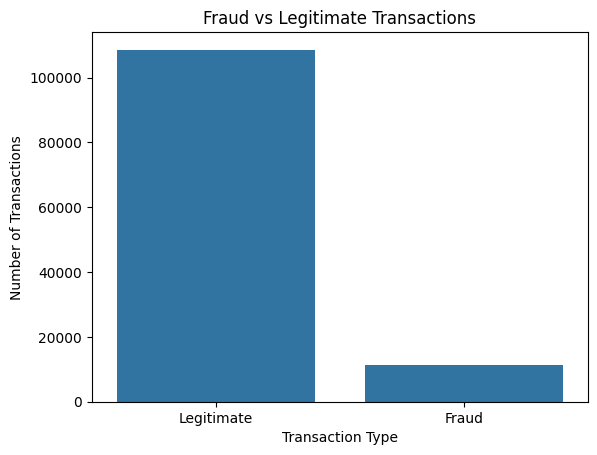

In [43]:
sns.countplot(data=df_clean, x='is_fraud')
plt.title('Fraud vs Legitimate Transactions')
plt.xlabel('Transaction Type')
plt.ylabel('Number of Transactions')
plt.xticks([0, 1], ['Legitimate', 'Fraud'])
plt.show()

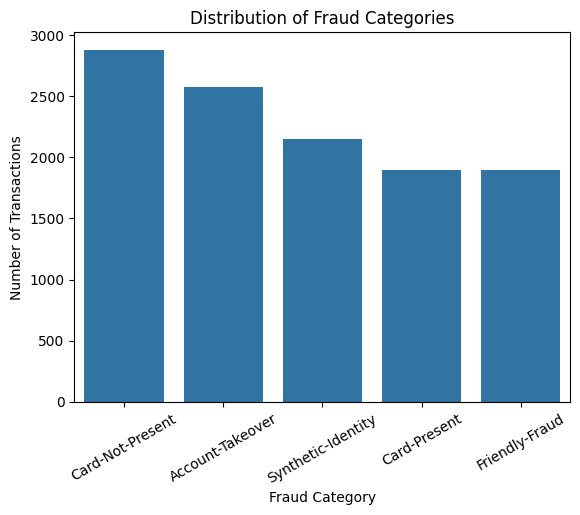

In [44]:
sns.countplot(
    data=fraud,
    x='fraud_type',
    order=fraud['fraud_type'].value_counts().index
)
plt.title('Distribution of Fraud Categories')
plt.xlabel('Fraud Category')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=30)
plt.show()

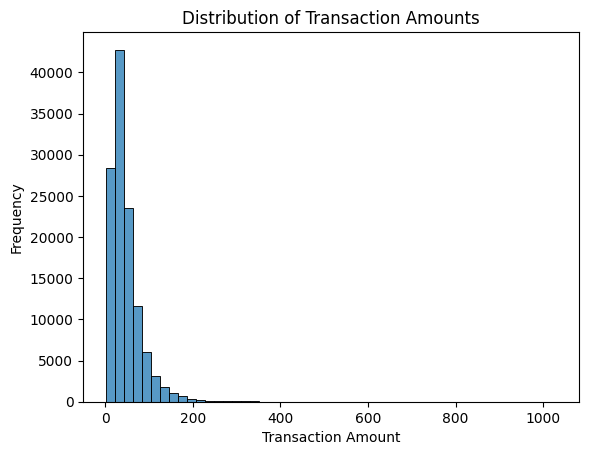

In [45]:
sns.histplot(
    data=df_clean,
    x='transaction_amount',
    bins=50
)
plt.title('Distribution of Transaction Amounts')
plt.xlabel('Transaction Amount')
plt.ylabel('Frequency')
plt.show()

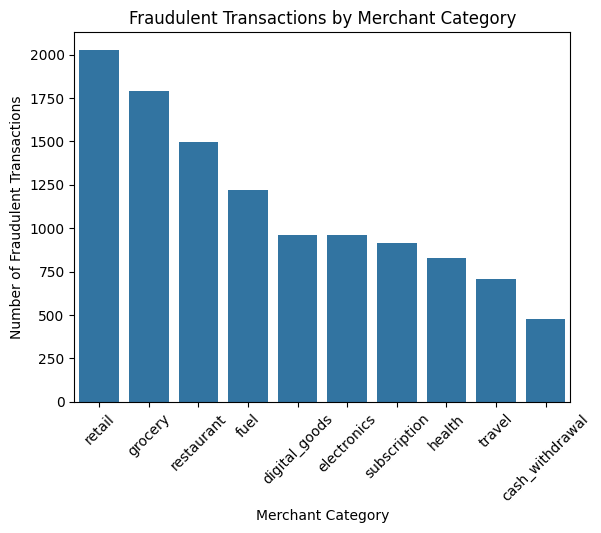

In [47]:
fraud_by_merchant = fraud['merchant_category'].value_counts()
sns.barplot(
    x=fraud_by_merchant.index,
    y=fraud_by_merchant.values
)
plt.title('Fraudulent Transactions by Merchant Category')
plt.xlabel('Merchant Category')
plt.ylabel('Number of Fraudulent Transactions')
plt.xticks(rotation=45)
plt.show()

In [48]:
monthly_transactions = df_clean.groupby('month').size()

In [49]:
monthly_fraud = fraud.groupby('month').size()

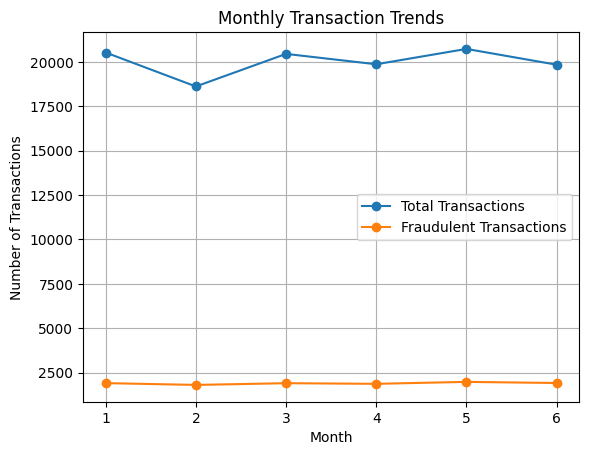

In [50]:
plt.plot(
    monthly_transactions.index,
    monthly_transactions.values,
    marker='o',
    label='Total Transactions'
)
plt.plot(
    monthly_fraud.index,
    monthly_fraud.values,
    marker='o',
    label='Fraudulent Transactions'
)
plt.title('Monthly Transaction Trends')
plt.xlabel('Month')
plt.ylabel('Number of Transactions')
plt.xticks(range(1,7))
plt.legend()
plt.grid(True)
plt.show()

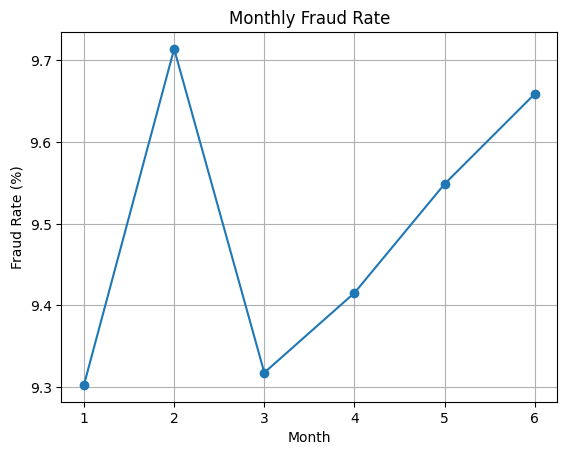

In [51]:
monthly_fraud_rate = df_clean.groupby('month')['is_fraud'].mean() * 100
plt.plot(
    monthly_fraud_rate.index,
    monthly_fraud_rate.values,
    marker='o'
)
plt.title('Monthly Fraud Rate')
plt.xlabel('Month')
plt.ylabel('Fraud Rate (%)')
plt.xticks(range(1,7))
plt.grid(True)
plt.show()

In [52]:
df_clean['transaction_amount'].mean()

np.float64(46.3277025)

In [53]:
df_clean.groupby('is_fraud')['transaction_amount'].mean()

,transaction_amount
is_fraud,
0,43.887321
1,69.604877


In [54]:
df_clean['transaction_amount'].median()

36.29

In [55]:
df_clean.groupby('is_fraud')['transaction_amount'].median()

,transaction_amount
is_fraud,
0,34.87
1,54.84


In [56]:
df_clean['transaction_amount'].std()

36.97235241551281

In [57]:
df_clean.groupby('is_fraud')['transaction_amount'].std()

,transaction_amount
is_fraud,
0,33.779891
1,54.064953


In [58]:
df_clean['transaction_amount'].quantile([0.25, 0.50, 0.75])

,transaction_amount
0.25,22.72
0.50,36.29
0.75,57.90


In [59]:
df_clean.groupby('is_fraud')['transaction_amount'].quantile([0.25, 0.50, 0.75])

is_fraud      
0         0.25    22.030
          0.50    34.870
          0.75    55.010
1         0.25    34.575
          0.50    54.840
          0.75    87.315
Name: transaction_amount, dtype: float64

In [60]:
Q1 = df_clean['transaction_amount'].quantile(0.25)
Q3 = df_clean['transaction_amount'].quantile(0.75)
IQR = Q3 - Q1
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 22.72
Q3: 57.9
IQR: 35.18


In [61]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Lower Bound: -30.049999999999997
Upper Bound: 110.66999999999999


In [62]:
outliers = df_clean[
    (df_clean['transaction_amount'] < lower_bound) |
    (df_clean['transaction_amount'] > upper_bound)
]
print("Number of Outliers:", len(outliers))

Number of Outliers: 6581


In [63]:
df_clean[['transaction_datetime',
          'transaction_hour',
          'transaction_day_of_week',
          'month',
          'is_weekend']].head(10)

,transaction_datetime,transaction_hour,transaction_day_of_week,month,is_weekend
0,2026-01-01 00:00:00,0,Thursday,1,0
1,2026-01-01 00:00:00,0,Thursday,1,0
2,2026-01-01 00:03:00,0,Thursday,1,0
3,2026-01-01 00:04:00,0,Thursday,1,0
4,2026-01-01 00:05:00,0,Thursday,1,0
5,2026-01-01 00:05:00,0,Thursday,1,0
6,2026-01-01 00:05:00,0,Thursday,1,0
7,2026-01-01 00:07:00,0,Thursday,1,0
8,2026-01-01 00:11:00,0,Thursday,1,0
9,2026-01-01 00:12:00,0,Thursday,1,0


In [64]:
features = ['transaction_amount','merchant_category','merchant_country','transaction_hour', 'transaction_day_of_week','month','is_weekend',
            'card_present', 'customer_age','customer_country','account_age_days','credit_limit','credit_score','transactions_last_24h',
             'distance_from_home_km', 'international_transaction', 'high_risk_country','transaction_channel','device_type','failed_auth_attempts_24h']


In [65]:
missing_columns = [col for col in features if col not in df_clean.columns]
print("Missing columns:", missing_columns)

Missing columns: []


In [66]:
X = df_clean[features]
y = df_clean['is_fraud']

In [67]:
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
print(numerical_features)

['transaction_amount', 'transaction_hour', 'month', 'is_weekend', 'card_present', 'customer_age', 'account_age_days', 'credit_limit', 'credit_score', 'transactions_last_24h', 'distance_from_home_km', 'international_transaction', 'high_risk_country', 'failed_auth_attempts_24h']


In [68]:
categorical_features = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()
print(categorical_features)

['merchant_category', 'merchant_country', 'transaction_day_of_week', 'customer_country', 'transaction_channel', 'device_type']


In [69]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

In [70]:
numerical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [71]:
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

In [72]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ])

In [73]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [74]:
lr_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

In [75]:
lr_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['transaction_amount',
                                                   'transaction_hour', 'month',
                                                   'is_weekend', 'card_present',
                                                   'customer_age',
                                                   'account_age_days',
                                                   'credit_limit',
                                                   'credit_score',
                                                   'transactions_last_24h',
                                                   'distance_from_home_km'...
                                                   'high_risk_country',
                                                   'failed_auth_attempts_24h']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['merchant_category',
                                                   'merchant_country',
                                                   'transaction_day_of_week',
                                                   'customer_country',
                                                   'transaction_channel',
                                                   'device_type'])])),
                ('classifier', LogisticRegression(max_iter=1000))])

In [76]:
y_pred_lr = lr_model.predict(X_test)

In [77]:
accuracy_lr = accuracy_score(y_test, y_pred_lr)
print("Accuracy:", accuracy_lr)

Accuracy: 0.9811666666666666


In [78]:
precision_lr = precision_score(y_test, y_pred_lr)
print("Precision:", precision_lr)

Precision: 0.9542060726729716


In [79]:
recall_lr = recall_score(y_test, y_pred_lr)
print("Recall:", recall_lr)

Recall: 0.841897233201581


In [80]:
f1_lr = f1_score(y_test, y_pred_lr)
print("F1 Score:", f1_lr)

F1 Score: 0.894540363975735


In [81]:
cm_lr = confusion_matrix(y_test, y_pred_lr)
print("Confusion Matrix:", cm_lr)

Confusion Matrix: [[21631    92]
 [  360  1917]]


In [82]:
dt_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

In [83]:
dt_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['transaction_amount',
                                                   'transaction_hour', 'month',
                                                   'is_weekend', 'card_present',
                                                   'customer_age',
                                                   'account_age_days',
                                                   'credit_limit',
                                                   'credit_score',
                                                   'transactions_last_24h',
                                                   'distance_from_home_km'...
                                                   'high_risk_country',
                                                   'failed_auth_attempts_24h']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['merchant_category',
                                                   'merchant_country',
                                                   'transaction_day_of_week',
                                                   'customer_country',
                                                   'transaction_channel',
                                                   'device_type'])])),
                ('classifier', DecisionTreeClassifier(random_state=42))])

In [84]:
y_pred_dt = dt_model.predict(X_test)
print(y_pred_dt[:20])

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [85]:
accuracy_dt = accuracy_score(y_test, y_pred_dt)
print("Accuracy:", accuracy_dt)

Accuracy: 0.9724166666666667


In [86]:
precision_dt = precision_score(y_test, y_pred_dt)
print("Precision:", precision_dt)

Precision: 0.8509343763581052


In [87]:
recall_dt = recall_score(y_test, y_pred_dt)
print("Recall:", recall_dt)

Recall: 0.8599033816425121


In [88]:
f1_dt = f1_score(y_test, y_pred_dt)
print("F1 Score:", f1_dt)

F1 Score: 0.855395369156837


In [89]:
cm_dt = confusion_matrix(y_test, y_pred_dt)
print("Confusion Matrix:", cm_dt)

Confusion Matrix: [[21380   343]
 [  319  1958]]


In [90]:
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
    ))
])

In [91]:
rf_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['transaction_amount',
                                                   'transaction_hour', 'month',
                                                   'is_weekend', 'card_present',
                                                   'customer_age',
                                                   'account_age_days',
                                                   'credit_limit',
                                                   'credit_score',
                                                   'transactions_last_24h',
                                                   'distance_from_home_km'...
                                                   'high_risk_country',
                                                   'failed_auth_attempts_24h']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['merchant_category',
                                                   'merchant_country',
                                                   'transaction_day_of_week',
                                                   'customer_country',
                                                   'transaction_channel',
                                                   'device_type'])])),
                ('classifier', RandomForestClassifier(random_state=42))])

In [92]:
y_pred_rf = rf_model.predict(X_test)
print(y_pred_rf[:20])

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [93]:
comparison_rf = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred_rf
})

comparison_rf.head(20)

,Actual,Predicted
0,0,0
1,0,0
2,0,0
3,1,0
4,0,0
5,0,0
6,0,0
7,0,0
8,0,0
9,0,0


In [94]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print("Accuracy:", accuracy_rf)

Accuracy: 0.9837083333333333


In [95]:
precision_rf = precision_score(y_test, y_pred_rf)
print("Precision:", precision_rf)

Precision: 0.9700897308075773


In [96]:
recall_rf = recall_score(y_test, y_pred_rf)
print("Recall:", recall_rf)

Recall: 0.8546332894158981


In [97]:
f1_rf = f1_score(y_test, y_pred_rf)
print("F1 Score:", f1_rf)

F1 Score: 0.9087088489376606


In [98]:
cm_rf = confusion_matrix(y_test, y_pred_rf)
print("Confusion Matrix:", cm_rf)

Confusion Matrix: [[21663    60]
 [  331  1946]]


In [99]:
from imblearn.over_sampling import SMOTE

In [100]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [101]:
print("Before SMOTE:")
print(y_train.value_counts())

Before SMOTE:
is_fraud
0    86890
1     9110
Name: count, dtype: int64


In [102]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_processed,
    y_train
)

In [103]:
print("After SMOTE:")
print(y_train_smote.value_counts())

After SMOTE:
is_fraud
0    86890
1    86890
Name: count, dtype: int64


In [104]:
from imblearn.over_sampling import SMOTENC

In [105]:
categorical_indices = [
    X_train.columns.get_loc(col)
    for col in categorical_features
]

smote_nc = SMOTENC(
    categorical_features=categorical_indices,
    random_state=42
)

X_train_smote, y_train_smote = smote_nc.fit_resample(
    X_train,
    y_train
)

In [106]:
print(y_train_smote.value_counts())

is_fraud
0    86890
1    86890
Name: count, dtype: int64


In [107]:
lr_smote_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

lr_smote_model.fit(X_train_smote, y_train_smote)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['transaction_amount',
                                                   'transaction_hour', 'month',
                                                   'is_weekend', 'card_present',
                                                   'customer_age',
                                                   'account_age_days',
                                                   'credit_limit',
                                                   'credit_score',
                                                   'transactions_last_24h',
                                                   'distance_from_home_km'...
                                                   'high_risk_country',
                                                   'failed_auth_attempts_24h']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['merchant_category',
                                                   'merchant_country',
                                                   'transaction_day_of_week',
                                                   'customer_country',
                                                   'transaction_channel',
                                                   'device_type'])])),
                ('classifier', LogisticRegression(max_iter=1000))])

In [108]:
dt_smote_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

dt_smote_model.fit(X_train_smote, y_train_smote)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['transaction_amount',
                                                   'transaction_hour', 'month',
                                                   'is_weekend', 'card_present',
                                                   'customer_age',
                                                   'account_age_days',
                                                   'credit_limit',
                                                   'credit_score',
                                                   'transactions_last_24h',
                                                   'distance_from_home_km'...
                                                   'high_risk_country',
                                                   'failed_auth_attempts_24h']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['merchant_category',
                                                   'merchant_country',
                                                   'transaction_day_of_week',
                                                   'customer_country',
                                                   'transaction_channel',
                                                   'device_type'])])),
                ('classifier', DecisionTreeClassifier(random_state=42))])

In [109]:
rf_smote_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
    ))

])
rf_smote_model.fit(X_train_smote, y_train_smote)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['transaction_amount',
                                                   'transaction_hour', 'month',
                                                   'is_weekend', 'card_present',
                                                   'customer_age',
                                                   'account_age_days',
                                                   'credit_limit',
                                                   'credit_score',
                                                   'transactions_last_24h',
                                                   'distance_from_home_km'...
                                                   'high_risk_country',
                                                   'failed_auth_attempts_24h']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['merchant_category',
                                                   'merchant_country',
                                                   'transaction_day_of_week',
                                                   'customer_country',
                                                   'transaction_channel',
                                                   'device_type'])])),
                ('classifier', RandomForestClassifier(random_state=42))])

In [110]:
y_pred_lr_smote = lr_smote_model.predict(X_test)

y_pred_dt_smote = dt_smote_model.predict(X_test)

y_pred_rf_smote = rf_smote_model.predict(X_test)

In [111]:
accuracy_lr_smote = accuracy_score(y_test, y_pred_lr_smote)
print("Accuracy:", accuracy_lr_smote)

precision_lr_smote = precision_score(y_test, y_pred_lr_smote)
print("Precision:", precision_lr_smote)

recall_lr_smote = recall_score(y_test, y_pred_lr_smote)
print("Recall:", recall_lr_smote)

f1_lr_smote = f1_score(y_test, y_pred_lr_smote)
print("F1 Score:", f1_lr_smote)

Accuracy: 0.9650416666666667
Precision: 0.7752679938744257
Recall: 0.8893280632411067
F1 Score: 0.8283902638576396


In [112]:
accuracy_dt_smote = accuracy_score(y_test, y_pred_dt_smote)
print("Accuracy:", accuracy_dt_smote)

precision_dt_smote = precision_score(y_test, y_pred_dt_smote)
print("Precision:", precision_dt_smote)

recall_dt_smote = recall_score(y_test, y_pred_dt_smote)
print("Recall:", recall_dt_smote)

f1_dt_smote = f1_score(y_test, y_pred_dt_smote)
print("F1 Score:", f1_dt_smote)

Accuracy: 0.955
Precision: 0.7106652587117213
Recall: 0.8866930171277997
F1 Score: 0.7889800703399765


In [113]:
accuracy_rf_smote = accuracy_score(y_test, y_pred_rf_smote)
print("Accuracy:", accuracy_rf_smote)

precision_rf_smote = precision_score(y_test, y_pred_rf_smote)
print("Precision:", precision_rf_smote)

recall_rf_smote = recall_score(y_test, y_pred_rf_smote)
print("Recall:", recall_rf_smote)

f1_rf_smote = f1_score(y_test, y_pred_rf_smote)
print("F1 Score:", f1_rf_smote)

Accuracy: 0.9787916666666666
Precision: 0.8823529411764706
Recall: 0.8959156785243741
F1 Score: 0.8890825887993027


In [133]:
smote_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest'],
    'Accuracy Before SMOTE': [accuracy_lr, accuracy_dt, accuracy_rf],
    'Accuracy After SMOTE': [accuracy_lr_smote, accuracy_dt_smote, accuracy_rf_smote],
    'Precision Before SMOTE': [precision_lr, precision_dt, precision_rf],
    'Precision After SMOTE': [precision_lr_smote, precision_dt_smote, precision_rf_smote],
    'Recall Before SMOTE': [recall_lr, recall_dt, recall_rf],
    'Recall After SMOTE': [recall_lr_smote, recall_dt_smote, recall_rf_smote],
    'F1 Before SMOTE': [f1_lr, f1_dt, f1_rf],
    'F1 After SMOTE': [f1_lr_smote, f1_dt_smote, f1_rf_smote]
})

smote_comparison

,Model,Accuracy Before SMOTE,Accuracy After SMOTE,Precision Before SMOTE,Precision After SMOTE,Recall Before SMOTE,Recall After SMOTE,F1 Before SMOTE,F1 After SMOTE
0,Logistic Regression,0.981167,0.965042,0.954206,0.775268,0.841897,0.889328,0.894540,0.828390
1,Decision Tree,0.972417,0.955000,0.850934,0.710665,0.859903,0.886693,0.855395,0.788980
2,Random Forest,0.983708,0.978792,0.970090,0.882353,0.854633,0.895916,0.908709,0.889083


In [134]:
best_model = smote_comparison.loc[
    smote_comparison['F1 After SMOTE'].idxmax(), 'Model'
]

print("Best Model:", best_model)

Best Model: Random Forest


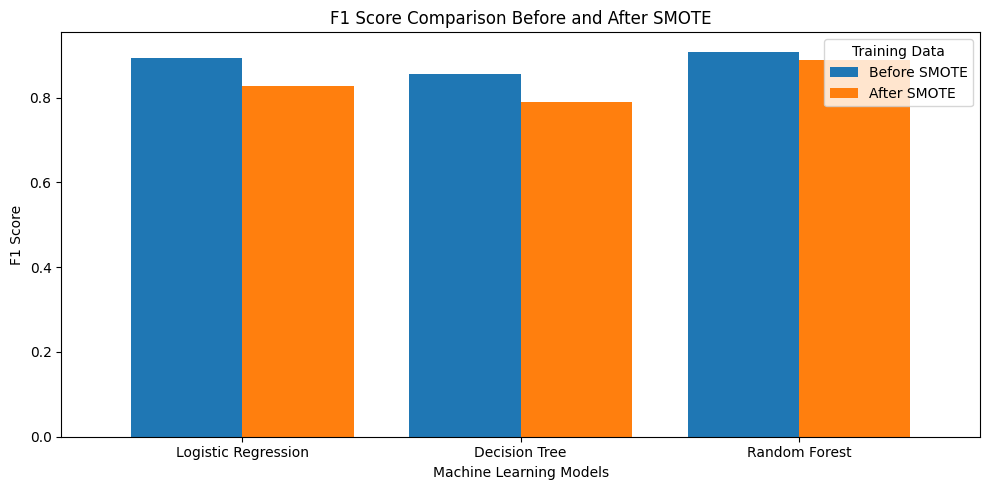

In [129]:
f1_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest'],
    'Before SMOTE': [f1_lr, f1_dt, f1_rf],
    'After SMOTE': [f1_lr_smote, f1_dt_smote, f1_rf_smote]
})

f1_comparison.set_index('Model').plot(
    kind='bar',
    figsize=(10, 5),
    width=0.8
)

plt.title('F1 Score Comparison Before and After SMOTE')
plt.ylabel('F1 Score')
plt.xlabel('Machine Learning Models')
plt.xticks(rotation=0)
plt.legend(title='Training Data')
plt.tight_layout()
plt.show()

In [114]:
fraud_data = df_clean[df_clean['is_fraud'] == 1].copy()

X_multi = fraud_data[features]
y_multi = fraud_data['fraud_type']

print("Dataset shape:", X_multi.shape)
print("\nFraud category distribution:")
print(y_multi.value_counts())

Dataset shape: (11387, 20)

Fraud category distribution:
fraud_type
Card-Not-Present      2879
Account-Takeover      2571
Synthetic-Identity    2146
Card-Present          1898
Friendly-Fraud        1893
Name: count, dtype: int64


In [115]:
X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(X_multi,y_multi,test_size=0.2,random_state=42,stratify=y_multi)

In [116]:
numerical_features_multi = X_train_multi.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features_multi = X_train_multi.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

numerical_transformer_multi = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer_multi = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor_multi = ColumnTransformer(transformers=[
    ('num', numerical_transformer_multi, numerical_features_multi),
    ('cat', categorical_transformer_multi, categorical_features_multi)
])

In [117]:
lr_multi_model = Pipeline([
    ('preprocessor', preprocessor_multi),
    ('classifier', LogisticRegression(max_iter=1000))
])

lr_multi_model.fit(X_train_multi, y_train_multi)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['transaction_amount',
                                                   'transaction_hour', 'month',
                                                   'is_weekend', 'card_present',
                                                   'customer_age',
                                                   'account_age_days',
                                                   'credit_limit',
                                                   'credit_score',
                                                   'transactions_last_24h',
                                                   'distance_from_home_km'...
                                                   'high_risk_country',
                                                   'failed_auth_attempts_24h']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['merchant_category',
                                                   'merchant_country',
                                                   'transaction_day_of_week',
                                                   'customer_country',
                                                   'transaction_channel',
                                                   'device_type'])])),
                ('classifier', LogisticRegression(max_iter=1000))])

In [118]:
y_pred_lr_multi = lr_multi_model.predict(X_test_multi)

In [119]:
accuracy_lr_multi = accuracy_score(y_test_multi, y_pred_lr_multi)
print("Accuracy:", accuracy_lr_multi)

precision_lr_multi = precision_score(y_test_multi, y_pred_lr_multi, average='macro')
print("Precision:", precision_lr_multi)

recall_lr_multi = recall_score(y_test_multi, y_pred_lr_multi, average='macro')
print("Recall:", recall_lr_multi)

f1_lr_multi = f1_score(y_test_multi, y_pred_lr_multi, average='macro')
print("F1 Score:", f1_lr_multi)

Accuracy: 0.7129060579455663
Precision: 0.7040302747418965
Recall: 0.7044475100326506
F1 Score: 0.6981292994543887


In [120]:
dt_multi_model = Pipeline([
    ('preprocessor', preprocessor_multi),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

dt_multi_model.fit(X_train_multi, y_train_multi)

y_pred_dt_multi = dt_multi_model.predict(X_test_multi)

In [121]:
accuracy_dt_multi = accuracy_score(y_test_multi, y_pred_dt_multi)
print("Accuracy:", accuracy_dt_multi)

precision_dt_multi = precision_score(y_test_multi, y_pred_dt_multi, average='macro')
print("Precision:", precision_dt_multi)

recall_dt_multi = recall_score(y_test_multi, y_pred_dt_multi, average='macro')
print("Recall:", recall_dt_multi)

f1_dt_multi = f1_score(y_test_multi, y_pred_dt_multi, average='macro')
print("F1 Score:", f1_dt_multi)

Accuracy: 0.617208077260755
Precision: 0.6117194001860686
Recall: 0.6096120119195859
F1 Score: 0.6105415093426398


In [122]:
rf_multi_model = Pipeline([
      ('preprocessor', preprocessor_multi),
      ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42,

   ))
   ])

rf_multi_model.fit(X_train_multi, y_train_multi)

y_pred_rf_multi = rf_multi_model.predict(X_test_multi)


In [123]:
accuracy_rf_multi = accuracy_score(y_test_multi, y_pred_rf_multi)
print("Accuracy:", accuracy_rf_multi)

precision_rf_multi = precision_score(y_test_multi, y_pred_rf_multi, average='macro')
print("Precision:", precision_rf_multi)

recall_rf_multi = recall_score(y_test_multi, y_pred_rf_multi, average='macro')
print("Recall:", recall_rf_multi)

f1_rf_multi = f1_score(y_test_multi, y_pred_rf_multi, average='macro')
print("F1 Score:", f1_rf_multi)

Accuracy: 0.7129060579455663
Precision: 0.7003930655893679
Recall: 0.7002727483583951
F1 Score: 0.6928375016771064


In [124]:
multi_model_comparison = pd.DataFrame({
      'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest'],
      'Accuracy': [accuracy_lr_multi, accuracy_dt_multi, accuracy_rf_multi],
      'Precision': [precision_lr_multi, precision_dt_multi, precision_rf_multi],
      'Recall': [recall_lr_multi, recall_dt_multi, recall_rf_multi],
      'F1 Score': [f1_lr_multi, f1_dt_multi, f1_rf_multi]
                      })
multi_model_comparison.sort_values(
                          by='F1 Score',
                              ascending=False
                              )


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.712906,0.704030,0.704448,0.698129
2,Random Forest,0.712906,0.700393,0.700273,0.692838
1,Decision Tree,0.617208,0.611719,0.609612,0.610542


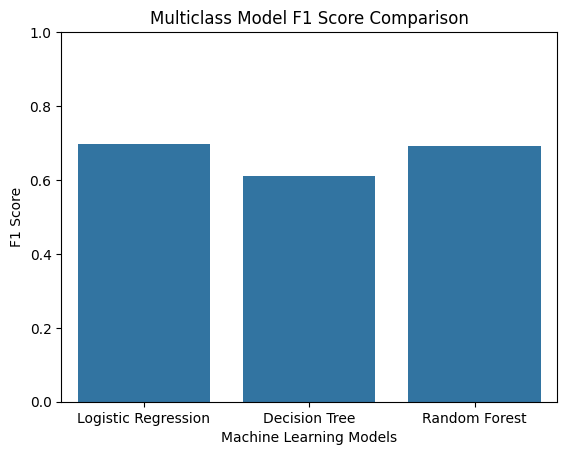

In [125]:
sns.barplot(
    data=multi_model_comparison,
        x='Model',
            y='F1 Score'
            )

plt.title('Multiclass Model F1 Score Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('F1 Score')
plt.ylim(0, 1)
plt.show()

In [130]:
best_multi_model = multi_model_comparison.loc[
    multi_model_comparison['F1 Score'].idxmax(), 'Model'
]

print("Best Multiclass Model:", best_multi_model)

Best Multiclass Model: Logistic Regression


In [126]:
df_drift = df_clean.copy()

df_drift['transaction_datetime'] = pd.to_datetime(
    df_drift['transaction_datetime']
    )
period_1 = df_drift[
        df_drift['transaction_datetime'].dt.month <= 3
        ]

period_2 = df_drift[
            df_drift['transaction_datetime'].dt.month >= 4
            ]

print("January to March:", period_1.shape)
print("April to June:", period_2.shape)

January to March: (59578, 73)
April to June: (60422, 73)


In [127]:
drift_comparison = pd.DataFrame({
      'Jan-Mar': period_1[
              ['transaction_amount', 'customer_age', 'credit_score',
                       'transactions_last_24h', 'distance_from_home_km']
                           ].mean(),

      'Apr-Jun': period_2[
              ['transaction_amount', 'customer_age', 'credit_score',
                'transactions_last_24h', 'distance_from_home_km']
                                                    ].mean()
                                                    })

display(drift_comparison)


,Jan-Mar,Apr-Jun
transaction_amount,47.025901,45.639257
customer_age,41.884102,41.832826
credit_score,688.710161,688.687150
transactions_last_24h,0.409144,0.435835
distance_from_home_km,18.449444,18.151385


In [128]:
df_drift['period'] = df_drift['transaction_datetime'].dt.month.map(
      lambda month: 'Jan-Mar' if month <= 3 else 'Apr-Jun'
      )

channel_comparison = pd.crosstab(
          df_drift['transaction_channel'],
              df_drift['period'],
                  normalize='columns'
                  ) * 100

display(channel_comparison.round(2))


period,Apr-Jun,Jan-Mar
transaction_channel,,
ATM,6.72,7.00
POS,41.98,41.73
ecommerce,29.59,29.37
mobile_app,16.61,16.63
recurring,5.10,5.28
